In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Настраиваем научный стиль (Правило 3: для дальтоников)
sns.set_theme(style="whitegrid", font_scale=1.2)
palette = sns.color_palette("colorblind")

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [2]:
# Генерируем данные (имитация наших логов)
np.random.seed(42) # Фиксируем случайность для воспроизводимости
models = ["XGBoost", "Random Forest"]
epsilons = [0.0, 0.01, 0.05, 0.1, 0.2]

data = []
for model in models:
    for eps in epsilons:
        base_f1 = 0.95 if model == "XGBoost" else 0.94
        drop = eps * (1.5 if model == "Random Forest" else 0.8)
        f1 = max(0.1, base_f1 - drop + np.random.normal(0, 0.01)) 
        latency = np.random.normal(12.5 if model == "XGBoost" else 15.2, 1.5)
        
        for _ in range(10): # 10 замеров для каждого условия
            data.append({
                "Model": model, 
                "Epsilon": eps, 
                "F1_Score": f1 + np.random.normal(0, 0.005),
                "Latency_ms": latency + np.random.normal(0, 0.2)
            })

df = pd.DataFrame(data)
print("Данные сгенерированы. Размер:", df.shape)
display(df.head())

Данные сгенерированы. Размер: (100, 4)


,Model,Epsilon,F1_Score,Latency_ms
0,XGBoost,0.0,0.958206,12.597210
1,XGBoost,0.0,0.953796,12.245776
2,XGBoost,0.0,0.962863,12.446090
3,XGBoost,0.0,0.952620,12.401116
4,XGBoost,0.0,0.952650,12.199458


C:\Users\bsiky\AppData\Local\Temp\ipykernel_19536\769181827.py:3: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.lineplot(


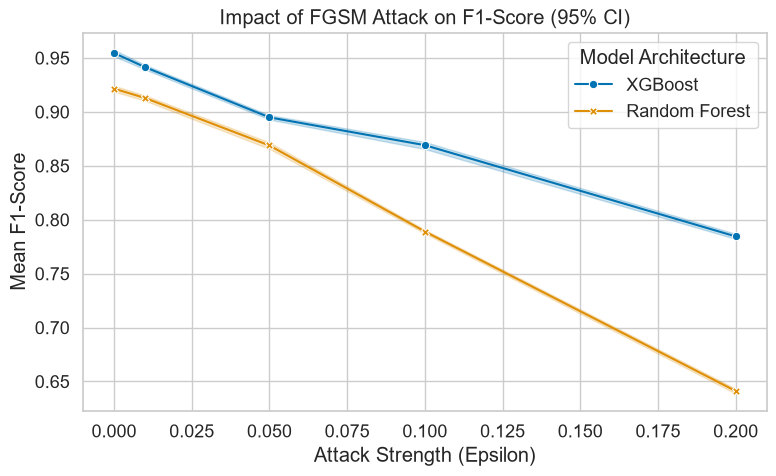

In [3]:
plt.figure(figsize=(8, 5))
# Строим график с 95% доверительным интервалом
sns.lineplot(
    data=df, x="Epsilon", y="F1_Score", hue="Model", 
    style="Model", markers=True, dashes=False, 
    palette=palette, errorbar=('ci', 95)
)
plt.title("Impact of FGSM Attack on F1-Score (95% CI)")
plt.xlabel("Attack Strength (Epsilon)")
plt.ylabel("Mean F1-Score") 
plt.legend(title="Model Architecture")
plt.tight_layout()

# Сохраняем графики в папку reports/figures
os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/fig1_attack_impact.pdf")
plt.savefig("reports/figures/fig1_attack_impact.png", dpi=300)
plt.show()

C:\Users\bsiky\AppData\Local\Temp\ipykernel_19536\2504452656.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


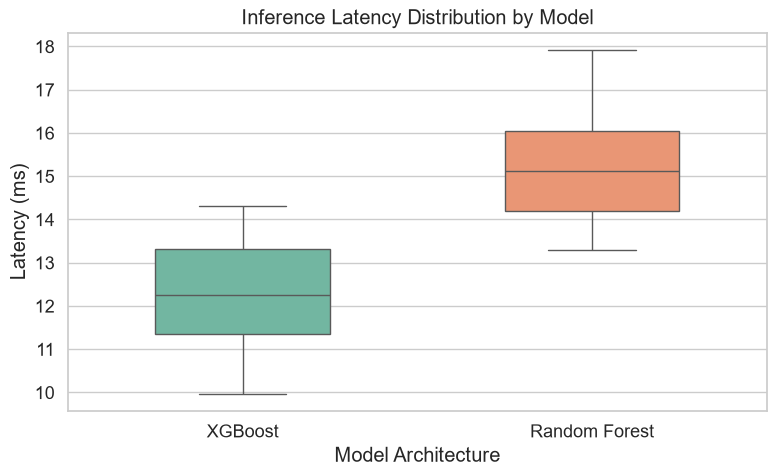

In [4]:
plt.figure(figsize=(8, 5))
# Строим Boxplot для разброса данных
sns.boxplot(
    data=df, x="Model", y="Latency_ms", 
    palette="Set2", width=0.5
)
plt.title("Inference Latency Distribution by Model")
plt.xlabel("Model Architecture")
plt.ylabel("Latency (ms)") 
plt.tight_layout()

plt.savefig("reports/figures/fig2_latency_distribution.pdf")
plt.savefig("reports/figures/fig2_latency_distribution.png", dpi=300)
plt.show()

In [5]:
os.makedirs("data/processed", exist_ok=True)
# Сохраняем медианы и перцентили (p95) как агрегированный CSV
summary = df.groupby(['Model', 'Epsilon']).agg(
    median_f1=('F1_Score', 'median'),
    p95_latency=('Latency_ms', lambda x: np.percentile(x, 95))
).reset_index()

summary.to_csv("data/processed/metrics_summary.csv", index=False)
print("Агрегированные данные сохранены в data/processed/metrics_summary.csv")

Агрегированные данные сохранены в data/processed/metrics_summary.csv
